<a href="https://colab.research.google.com/github/emiesabumukama-star/ace-module2-lab/blob/main/PixelCNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook, we'll walk through the steps required to train your own PixelCNN on the fashion MNIST dataset using Tensorflow distributions

In [1]:
import numpy as np
import os
os.makedirs("./output", exist_ok=True)
os.makedirs("./logs", exist_ok=True)

#import tensorflow as tf
#from tensorflow.keras import datasets, layers, models, optimizers, callbacks
#import tensorflow_probability as tfp
import tf_keras as keras
from tf_keras import datasets, layers, models, optimizers, callbacks
import tensorflow_probability as tfp
import tensorflow as tf

#from notebooks.utils import display
import matplotlib.pyplot as plt
def display(images, n=10, save_to=None):
    plt.figure(figsize=(10, 2))
    for i in range(min(n, len(images))):
        plt.subplot(1, n, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.axis("off")
    if save_to:
        plt.savefig(save_to)
    plt.show()

## 0. Parameters <a name="parameters"></a>

In [2]:
IMAGE_SIZE = 32
N_COMPONENTS = 5
EPOCHS = 10
BATCH_SIZE = 128

## 1. Prepare the data <a name="prepare"></a>

In [3]:
# Load the data
(x_train, _), (_, _) = datasets.fashion_mnist.load_data()

4422102/4422102 [==============================] - 1s 0us/step


In [4]:
# Preprocess the data


def preprocess(imgs):
    imgs = np.expand_dims(imgs, -1)
    imgs = tf.image.resize(imgs, (IMAGE_SIZE, IMAGE_SIZE)).numpy()
    return imgs


input_data = preprocess(x_train)

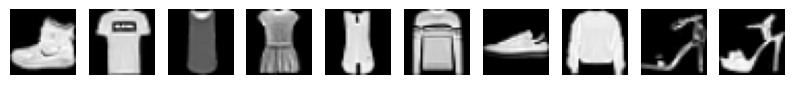

In [5]:
# Show some items of clothing from the training set
display(input_data)

## 2. Build the PixelCNN <a name="build"></a>

In [6]:
# Define a Pixel CNN network
dist = tfp.distributions.PixelCNN(
    image_shape=(IMAGE_SIZE, IMAGE_SIZE, 1),
    num_resnet=1,
    num_hierarchies=2,
    num_filters=32,
    num_logistic_mix=N_COMPONENTS,
    dropout_p=0.3,
)

# Define the model input
image_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 1))

# Define the log likelihood for the loss fn
log_prob = dist.log_prob(image_input)

# Define the model
pixelcnn = models.Model(inputs=image_input, outputs=log_prob)
pixelcnn.add_loss(-tf.reduce_mean(log_prob))

## 3. Train the PixelCNN <a name="train"></a>

In [7]:
# Compile and train the model
pixelcnn.compile(
    optimizer=optimizers.Adam(0.001),
)

In [8]:
tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")


class ImageGenerator(callbacks.Callback):
    def __init__(self, num_img):
        self.num_img = num_img

    def generate(self):
        return dist.sample(self.num_img).numpy()

    def on_epoch_end(self, epoch, logs=None):
        generated_images = self.generate()
        display(
            generated_images,
            n=self.num_img,
            save_to="./output/generated_img_%03d.png" % (epoch),
        )


img_generator_callback = ImageGenerator(num_img=2)

Layer _PixelCNNNetwork was created by passing
non-serializable argument values in `__init__()`,
and therefore the layer must override `get_config()` in
order to be serializable. Please implement `get_config()`.

Example:

class CustomLayer(keras.layers.Layer):
    def __init__(self, arg1, arg2, **kwargs):
        super().__init__(**kwargs)
        self.arg1 = arg1
        self.arg2 = arg2

    def get_config(self):
        config = super().get_config()
        config.update({
            "arg1": self.arg1,
            "arg2": self.arg2,
        })
        return config


Epoch 1/10
  6/469 [..............................] - ETA: 1:35 - loss: 4360.9106

469/469 [==============================] - ETA: 0s - loss: 2392.7480

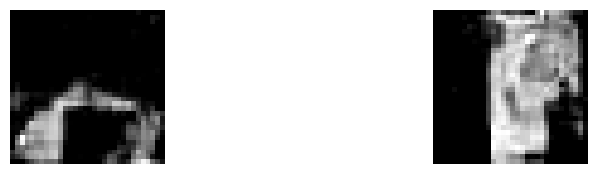

469/469 [==============================] - 264s 499ms/step - loss: 2392.7480
Epoch 2/10
469/469 [==============================] - ETA: 0s - loss: 2083.3455

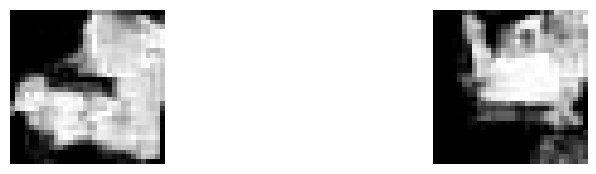

469/469 [==============================] - 234s 499ms/step - loss: 2083.3455
Epoch 3/10
469/469 [==============================] - ETA: 0s - loss: 1999.6832

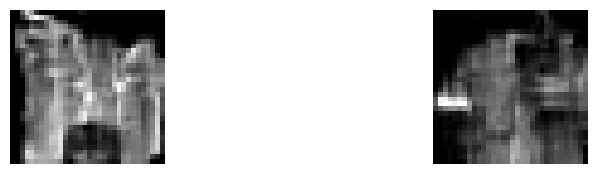

469/469 [==============================] - 233s 497ms/step - loss: 1999.6832
Epoch 4/10
469/469 [==============================] - ETA: 0s - loss: 1945.8279

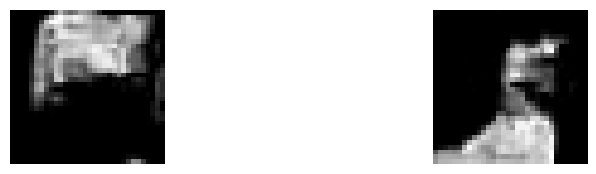

469/469 [==============================] - 232s 495ms/step - loss: 1945.8279
Epoch 5/10
469/469 [==============================] - ETA: 0s - loss: 1908.3535

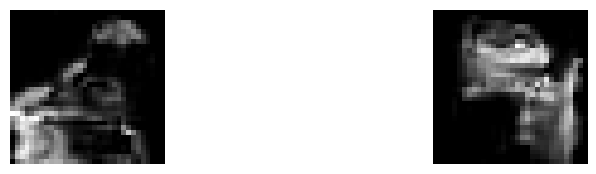

469/469 [==============================] - 232s 494ms/step - loss: 1908.3535
Epoch 6/10
469/469 [==============================] - ETA: 0s - loss: 1880.5759

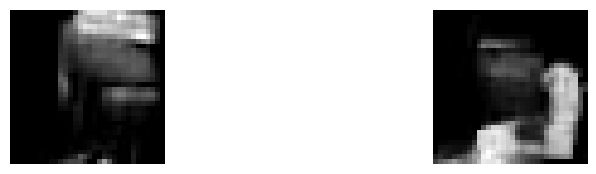

469/469 [==============================] - 231s 494ms/step - loss: 1880.5759
Epoch 7/10
469/469 [==============================] - ETA: 0s - loss: 1854.8705

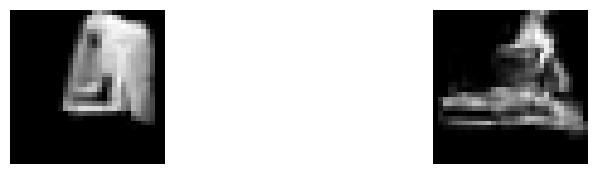

469/469 [==============================] - 230s 492ms/step - loss: 1854.8705
Epoch 8/10
469/469 [==============================] - ETA: 0s - loss: 1837.5874

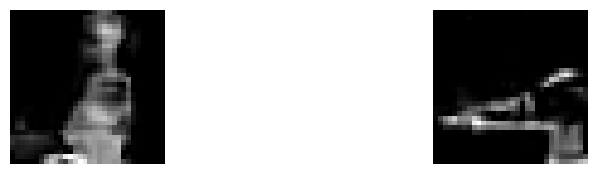

469/469 [==============================] - 235s 501ms/step - loss: 1837.5874
Epoch 9/10
469/469 [==============================] - ETA: 0s - loss: 1821.2120

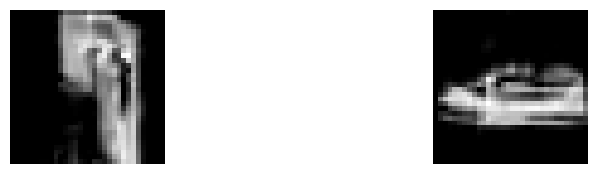

469/469 [==============================] - 233s 496ms/step - loss: 1821.2120
Epoch 10/10
469/469 [==============================] - ETA: 0s - loss: 1804.0544

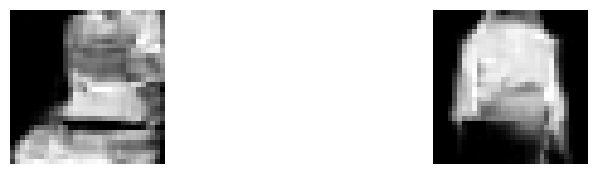

469/469 [==============================] - 235s 501ms/step - loss: 1804.0544


In [9]:
pixelcnn.fit(
    input_data,
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    verbose=True,
    callbacks=[tensorboard_callback, img_generator_callback],
)

## 4. Generate images <a name="generate"></a>

In [10]:
generated_images = img_generator_callback.generate()

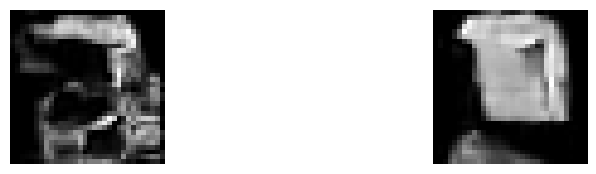

In [11]:
display(generated_images, n=img_generator_callback.num_img)